In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv("Monthly_Economic_Indicators.csv")
df

,Date,Calgary (CER) Unemployment rate (%),Alberta Unemployment Rate (%),Canada Unemployment rate (%),Calgary (CER) Total Employment ('000 Persons),Calgary (CER) Total Employment month-over-month change ('000 Persons),Calgary (CER) Total Employment year-over-year change ('000 Persons),Calgary (CMA) Average Hourly Wage Rate ($),City of Calgary Building Permits Residential Value ($),City of Calgary Building Permits Non-Residential Value ($),Calgary (City) Total Housing Starts (units),Calgary (CMA) Total Housing Starts (units),Calgary (CER) Retail Sales ($billions),Calgary (CMA) Inflation Rate (%change)
0,1984/06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202.0,NaN,0.02
1,1977/02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,579.0,NaN,0.07
2,1977/03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,468.0,NaN,0.08
3,1976/09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,692.0,NaN,0.07
4,1977/04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1227.0,NaN,0.09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
631,2024/08,0.07,0.07,0.07,1007.0,7.7,16.3,38.9,5.833727e+08,1.745231e+08,1437.0,1675.0,3.60,0.02
632,2024/09,0.07,0.07,0.07,1004.1,-2.9,20.7,38.8,6.251753e+08,2.026988e+08,1826.0,2090.0,3.67,0.02
633,2024/10,0.07,0.07,0.06,1004.4,0.3,28.8,38.7,5.307546e+08,1.565466e+08,2285.0,2690.0,NaN,0.03
634,2024/11,0.07,0.07,0.06,997.8,-6.6,32.6,38.7,4.767396e+08,7.275693e+08,2246.0,2548.0,NaN,0.03


#### Inspect and Clean Data:


In [4]:
# Display first few rows of the dataset
print("Initial Dataset Preview:")
display(df.head())

Initial Dataset Preview:


,Date,Calgary (CER) Unemployment rate (%),Alberta Unemployment Rate (%),Canada Unemployment rate (%),Calgary (CER) Total Employment ('000 Persons),Calgary (CER) Total Employment month-over-month change ('000 Persons),Calgary (CER) Total Employment year-over-year change ('000 Persons),Calgary (CMA) Average Hourly Wage Rate ($),City of Calgary Building Permits Residential Value ($),City of Calgary Building Permits Non-Residential Value ($),Calgary (City) Total Housing Starts (units),Calgary (CMA) Total Housing Starts (units),Calgary (CER) Retail Sales ($billions),Calgary (CMA) Inflation Rate (%change)
0,1984/06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,202.0,NaN,0.02
1,1977/02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,579.0,NaN,0.07
2,1977/03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,468.0,NaN,0.08
3,1976/09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,692.0,NaN,0.07
4,1977/04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1227.0,NaN,0.09


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 14 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   Date                                                                   636 non-null    object 
 1   Calgary (CER) Unemployment rate (%)                                    453 non-null    float64
 2   Alberta Unemployment Rate (%)                                          453 non-null    float64
 3   Canada Unemployment rate (%)                                           453 non-null    float64
 4   Calgary (CER) Total Employment ('000 Persons)                          453 non-null    float64
 5   Calgary (CER) Total Employment month-over-month change ('000 Persons)  284 non-null    float64
 6   Calgary (CER) Total Employment year-over-year change ('000 Persons)    273 non-null    flo

In [6]:
display(df.describe())

,Calgary (CER) Unemployment rate (%),Alberta Unemployment Rate (%),Canada Unemployment rate (%),Calgary (CER) Total Employment ('000 Persons),Calgary (CER) Total Employment month-over-month change ('000 Persons),Calgary (CER) Total Employment year-over-year change ('000 Persons),Calgary (CMA) Average Hourly Wage Rate ($),City of Calgary Building Permits Residential Value ($),City of Calgary Building Permits Non-Residential Value ($),Calgary (City) Total Housing Starts (units),Calgary (CMA) Total Housing Starts (units),Calgary (CER) Retail Sales ($billions),Calgary (CMA) Inflation Rate (%change)
count,453.000000,453.000000,453.000000,453.000000,284.000000,273.000000,333.000000,2.990000e+02,2.990000e+02,419.000000,635.000000,331.000000,635.000000
mean,0.066689,0.065210,0.077815,669.620751,1.483099,16.909890,26.594865,2.176400e+08,1.524060e+08,819.644391,864.801575,2.075317,0.041102
std,0.021689,0.019536,0.017072,184.922516,7.619836,28.058914,6.976679,1.344528e+08,1.209018e+08,389.247046,468.611472,0.796214,0.033545
min,0.030000,0.030000,0.050000,373.200000,-40.800000,-131.200000,15.400000,3.915911e+07,-3.795452e+07,134.000000,57.000000,0.790000,-0.030000
25%,0.050000,0.050000,0.070000,482.100000,-2.825000,7.400000,19.040000,1.289456e+08,8.148167e+07,553.500000,524.000000,1.285000,0.020000
50%,0.060000,0.060000,0.070000,684.800000,0.900000,18.800000,27.000000,1.793745e+08,1.190177e+08,768.000000,821.000000,2.060000,0.030000
75%,0.080000,0.080000,0.090000,836.800000,6.200000,28.500000,32.100000,2.777104e+08,1.848328e+08,988.500000,1105.500000,2.670000,0.060000
max,0.150000,0.150000,0.130000,1007.000000,32.700000,93.800000,38.900000,9.244110e+08,9.433636e+08,2884.000000,3068.000000,3.690000,0.140000


In [7]:
print("\nMissing values in the dataset:")
print(df.isnull().sum())
df.count()


Missing values in the dataset:
Date                                                                       0
Calgary (CER) Unemployment rate (%)                                      183
Alberta Unemployment Rate (%)                                            183
Canada Unemployment rate (%)                                             183
Calgary (CER) Total Employment ('000 Persons)                            183
Calgary (CER) Total Employment month-over-month change ('000 Persons)    352
Calgary (CER) Total Employment year-over-year change ('000 Persons)      363
Calgary (CMA) Average Hourly Wage Rate ($)                               303
City of Calgary Building Permits Residential Value ($)                   337
City of Calgary Building Permits Non-Residential Value ($)               337
Calgary (City) Total Housing Starts (units)                              217
Calgary (CMA) Total Housing Starts (units)                                 1
Calgary (CER) Retail Sales ($billions)      

Date                                                                     636
Calgary (CER) Unemployment rate (%)                                      453
Alberta Unemployment Rate (%)                                            453
Canada Unemployment rate (%)                                             453
Calgary (CER) Total Employment ('000 Persons)                            453
Calgary (CER) Total Employment month-over-month change ('000 Persons)    284
Calgary (CER) Total Employment year-over-year change ('000 Persons)      273
Calgary (CMA) Average Hourly Wage Rate ($)                               333
City of Calgary Building Permits Residential Value ($)                   299
City of Calgary Building Permits Non-Residential Value ($)               299
Calgary (City) Total Housing Starts (units)                              419
Calgary (CMA) Total Housing Starts (units)                               635
Calgary (CER) Retail Sales ($billions)                                   331

In [8]:
# Handle missing values: Drop or fill
df.dropna(inplace=True)  # Alternatively, you can use fillna()
df.isnull().sum()

Date                                                                     0
Calgary (CER) Unemployment rate (%)                                      0
Alberta Unemployment Rate (%)                                            0
Canada Unemployment rate (%)                                             0
Calgary (CER) Total Employment ('000 Persons)                            0
Calgary (CER) Total Employment month-over-month change ('000 Persons)    0
Calgary (CER) Total Employment year-over-year change ('000 Persons)      0
Calgary (CMA) Average Hourly Wage Rate ($)                               0
City of Calgary Building Permits Residential Value ($)                   0
City of Calgary Building Permits Non-Residential Value ($)               0
Calgary (City) Total Housing Starts (units)                              0
Calgary (CMA) Total Housing Starts (units)                               0
Calgary (CER) Retail Sales ($billions)                                   0
Calgary (CMA) Inflation R

In [9]:
# Ensure consistent data types
df['Date'] = pd.to_datetime(df['Date']) # Convert Date to datetime format
df.sort_values('Date', inplace=True)

C:\Users\Rikabi3li\AppData\Local\Temp\ipykernel_7516\1465590374.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date']) # Convert Date to datetime format


In [10]:
# Create new columns for the year, month, and day of the week
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.day_name()

In [11]:
# Display cleaned dataset preview
print("\nCleaned Dataset Preview:")
display(df.head())


Cleaned Dataset Preview:


,Date,Calgary (CER) Unemployment rate (%),Alberta Unemployment Rate (%),Canada Unemployment rate (%),Calgary (CER) Total Employment ('000 Persons),Calgary (CER) Total Employment month-over-month change ('000 Persons),Calgary (CER) Total Employment year-over-year change ('000 Persons),Calgary (CMA) Average Hourly Wage Rate ($),City of Calgary Building Permits Residential Value ($),City of Calgary Building Permits Non-Residential Value ($),Calgary (City) Total Housing Starts (units),Calgary (CMA) Total Housing Starts (units),Calgary (CER) Retail Sales ($billions),Calgary (CMA) Inflation Rate (%change),Year,Month,DayOfWeek
386,2002-03-01,0.05,0.05,0.08,605.1,-1.1,28.5,19.13,1.424768e+08,45105989.68,762.0,855.0,1.18,0.03,2002,3,Friday
387,2002-04-01,0.06,0.06,0.08,607.4,2.3,26.7,19.36,1.785122e+08,63427877.76,1102.0,1207.0,1.23,0.04,2002,4,Monday
388,2002-05-01,0.06,0.06,0.08,607.2,-0.2,19.3,19.47,1.411180e+08,94276137.00,1068.0,1292.0,1.25,0.01,2002,5,Wednesday
389,2002-06-01,0.06,0.06,0.08,609.9,2.7,9.0,19.39,1.640434e+08,54290605.62,1351.0,1563.0,1.25,0.01,2002,6,Saturday
390,2002-07-01,0.06,0.06,0.08,615.6,5.7,5.5,19.04,1.725499e+08,65087287.66,686.0,865.0,1.22,0.03,2002,7,Monday


In [12]:
df.shape

(271, 17)

### Exploratory Data Analysis and Visualization

#### 1. Compare Calgary's Unemployment Rate to Alberta and Canada


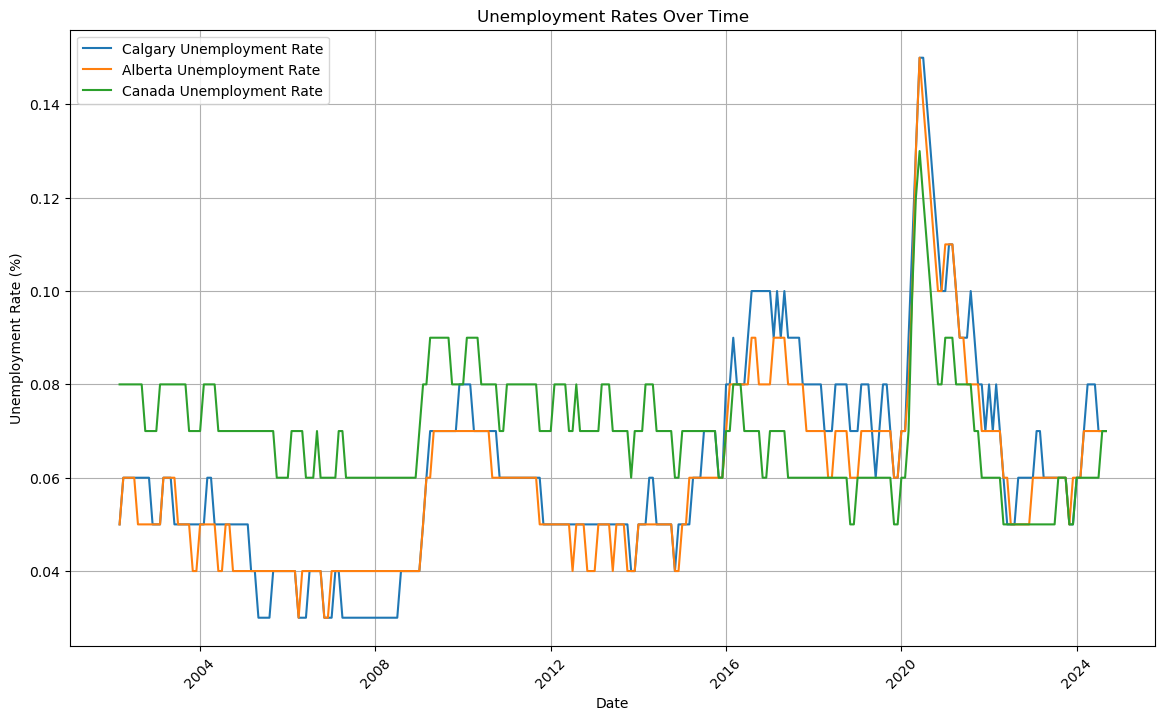

In [15]:
# Line graphs for unemployment rates, employment changes, and hourly wage rates
plt.figure(figsize=(14, 8))
plt.plot(df['Date'], df['Calgary (CER) Unemployment rate (%)'], label='Calgary Unemployment Rate')
plt.plot(df['Date'], df['Alberta Unemployment Rate (%)'], label='Alberta Unemployment Rate')
plt.plot(df['Date'], df['Canada Unemployment rate (%)'], label='Canada Unemployment Rate')
plt.title('Unemployment Rates Over Time')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

##### Trends and Correlations:

General Correlation:

Calgary, Alberta, and Canada's unemployment rates often move in sync, showing a correlation between local and national economic conditions.
2016-2020 Period:

During this period, there seems to be an increase in unemployment rates, particularly sharp in Calgary and Alberta compared to the national trend.
Post-2020 Period (Pandemic Impact):

A significant spike is observed around 2020, likely due to the global COVID-19 pandemic. This affected local and national unemployment rates substa

##### Peaks:

2020 Peak:

This spike indicates the economic impact of the pandemic, with Calgary and Alberta showing slightly higher peaks than Canada, suggesting regi nal vulnerabiliti
es.
Post-2020 Decline:

There is a downward trend f 2020 peak, suggesting recovery efforts are in place, although rates remain volatile.

##### Implications:

Economic Sensitivity:

Calgary and Alberta appear more sensitive to economic shocks compared to the national trend, possibly due to reliance on specific industries like oil and gas.
Policy and Recovery:

The peaks and trends highlight the need for targeted employment policies and economic diversification to enhance resilience.
Future Monitoring:

Continued monitoring of these trends is essential to assess recovery speed and the effectiveness of policy measures, especially in urban centers like Calgary.

This analysis helps understand regional economic health relative to national trends and informs policymakers and stakeholders on strategic planning.om the ntially.

#### 2. Trend Analysis of Calgary's Unemployment Rate


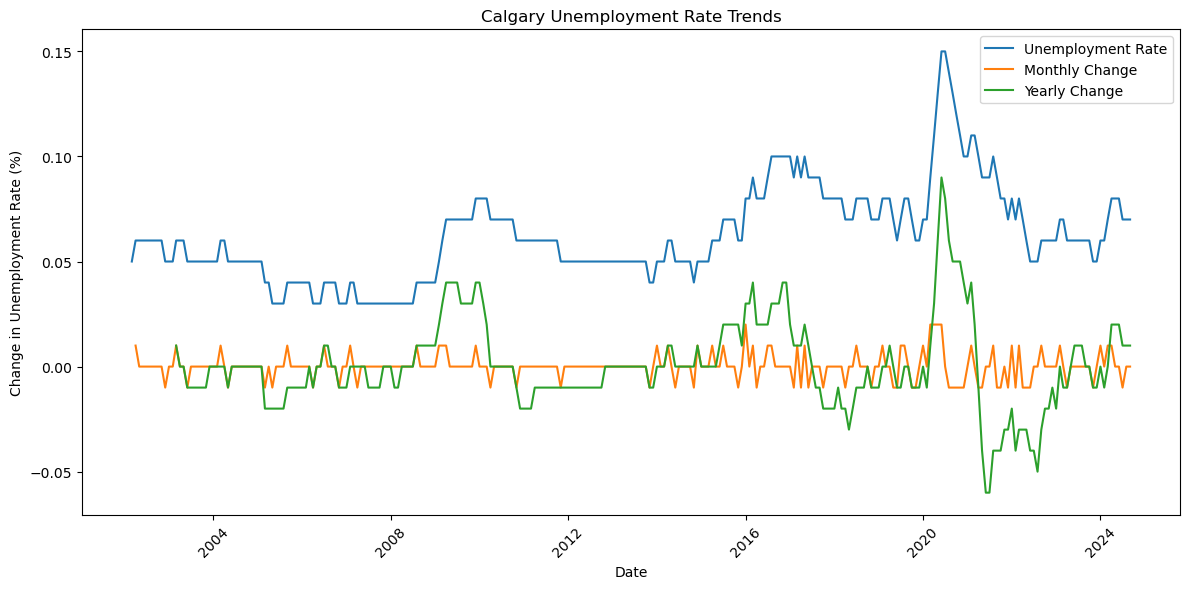

In [18]:
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

df['Monthly Change'] = df['Calgary (CER) Unemployment rate (%)'].diff()
df['Yearly Change'] = df['Calgary (CER) Unemployment rate (%)'].diff(12)

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Calgary (CER) Unemployment rate (%)'], label='Unemployment Rate')
plt.plot(df.index, df['Monthly Change'], label='Monthly Change')
plt.plot(df.index, df['Yearly Change'], label='Yearly Change')
plt.xlabel('Date')
plt.ylabel('Change in Unemployment Rate (%)')
plt.title('Calgary Unemployment Rate Trends')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Strong Correlations:

Unemployment Rate and Yearly Change:

There is a visible strong correlation between the unemployment rate and the yearly change, especially noticeable around the 2020 period. When the unemployment rate peaks, the yearly change also shows a significant spike or dtric.

Implication: This indicates that sharp changes in the unemployment rate are reflected more strongly on a yearly basis compared to monthly variations. Economic events or crises impacting employment heavily in one year are captured by the yearly change metric.

Monthly Change and Stability:

The monthly change remains relatively stable compared to the yearly change, suggesting less volatility on a month-to-month basis.

Implication: Short-term economic fluctuations might not drastically affect the unemployment rate each month, but cumulative effects are more visible over a year.

##### Implications:

Economic Events: The spike around 2020 is likely due to significant global events such as the COVID-19 pandemic, which caused drastic changes in unemployment rates worldwide. This kind of event can lead to large yearly changes and can drive economic policy response.

Policy and Planning: Policymakers and economic planners can use these correlations to assess how long-term strategies versus short-term tactics might affect employment. They could focus on measures that mitigate large yearly swings or capitalize on stable monthly trends.

Forecasting and Risk Management: Analysts can forecast future trends by examining past patterns in both monthly and yearly changes, helping businesses and governments prepare for potential employment challenges.

Overall, understanding these correlations helps in comprehending the broader economic narrative impacting unemployment trends and assists in deriving strategic insights for socio-economic planning.

### 3. Correlation between Wages and Unemployment Rates


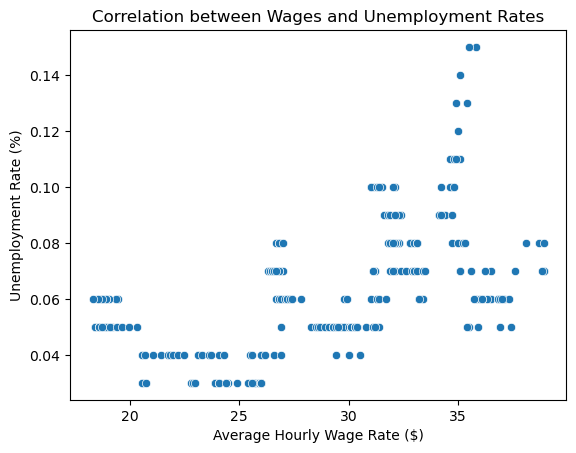

In [29]:
sns.scatterplot(x='Calgary (CMA) Average Hourly Wage Rate ($)', y='Calgary (CER) Unemployment rate (%)', data=df)
plt.title('Correlation between Wages and Unemployment Rates')
plt.xlabel('Average Hourly Wage Rate ($)')
plt.ylabel('Unemployment Rate (%)')
plt.show()

##### Trend/Correlation:

There appears to be a positive correlation, meaning that as the average hourly wage increases, the unemployment rate tends to increase as well. This is somewhat counterintuitive, as typically higher wages might be expected to correlate with lower unemployment due to increased consumer spending and economic activy. conditions.

##### Peaks:

There is a noticeable cluster of points where the wage ranges between $30 to $37, with unemployment rates often exceeding 0.08. This suggests that higher wage rates in this range coincide with higher unemployment rates

##### Implications:

The positive correlation could imply that industries or jobs with higher wages may also have higher barriers to entry, leading to higher unemployment.
It may reflect economic conditions where jobs are highly specialized or concentrated in a few sectors, leading to higher wages but also higher unemployment due to limited availability.
Alternatively, it might indicate areas where cost of living is high, and despite higher wages, unemployment remains elevated due to fewer job opportunities.

Overall, while the plot shows a trend, further analysis would be needed to understand the underlying causes and to consider other influencing factors, such as industry distribution, geographic variations, and economic conditions.

### 4. Inflation Rate and Retail Sales Analysis

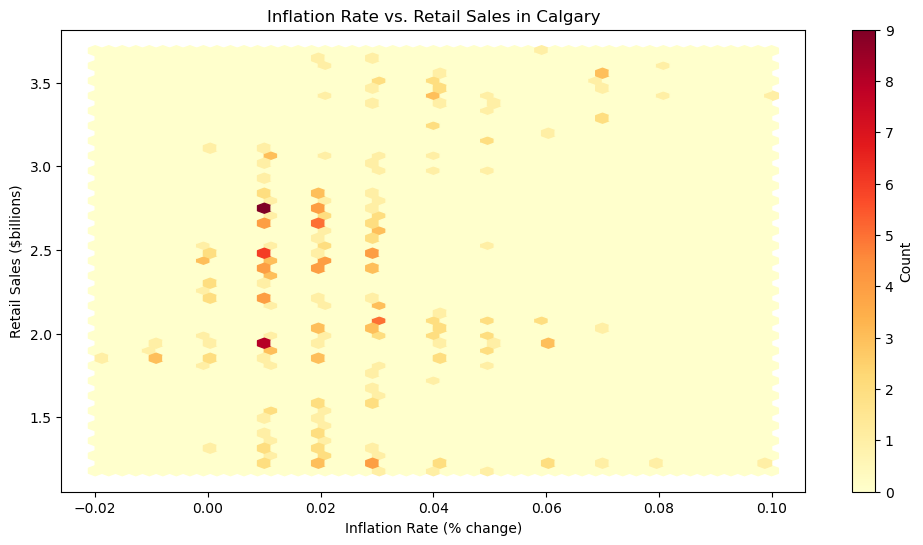

In [35]:
plt.figure(figsize=(12, 6))

# Create a 2D histogram (hexbin) instead of a scatter plot
hb = plt.hexbin(df['Calgary (CMA) Inflation Rate (%change)'],
                df['Calgary (CER) Retail Sales ($billions)'],
                gridsize=50, cmap='YlOrRd')

plt.colorbar(hb, label='Count')

plt.title('Inflation Rate vs. Retail Sales in Calgary')
plt.xlabel('Inflation Rate (% change)')
plt.ylabel('Retail Sales ($billions)')
plt.show()

##### Correlation Analysis:

Density Patterns:

There are higher concentrations of points when the inflation rate is around 0% to 3% and retail sales are between $2.0 billion to $2.5 billion.
Higher density regions are indicated by darker hexagons, primarily centered around these raed range.

Correlation Observation:

The plot does not exhibit a strong linear correlation; instead, it shows scattered data points.
The absence of a distinct upward or downward trend suggests a weak or no clear correlation between the inflation rate and retail sales within the observed range.

##### Implications:

Economic Interpretation:

The high density of points at lower inflation rates suggests that moderate inflation may be associated with stable retail sales figures.
The weak correlation implies that inflation rate changes may not directly influence retail sales within the observed range.

Business Strategy Considerations:

Retail businesses might not rely solely on inflation metrics to predict sales performance.
Other factors such as consumer confidence, employment rates, and external economic factors should also be considered when analyzing retail sales trends.

Policy Implications:

Policymakers should note that moderate inflation alone may not sufficiently explain retail sales behavior and need to consider a broader range of economic indicators to understand the retail market dynamics in Calgaring.